# BioLGCA 2D


# Introduction

To simulate the dynamics for longer times and record the steps we use the class method `timeevo`. It takes the keyword arguments `timesteps`, that sets the number of time steps to simulate. Also, all configurations can be recorded using `record=True`. To only record the density profile set `recorddens=True`. The total number of cells can be recorded with `recordN=True`, which is also the default.

In [2]:
import matplotlib
import IPython
import ipykernel
import matplotlib_inline
import fipy
import sympy
print("SymPy version:", sympy.__version__)
print("FiPy version:", fipy.__version__)
print("matplotlib:", matplotlib.__version__)
print("ipython:", IPython.__version__)
print("ipykernel:", ipykernel.__version__)
print("matplotlib_inline:", matplotlib_inline.__version__)

SymPy version: 1.14.0
FiPy version: 4.0.1
matplotlib: 3.10.6
ipython: 9.5.0
ipykernel: 6.30.1
matplotlib_inline: 0.1.7


In [3]:
%matplotlib notebook
from lgca import get_lgca

In [4]:
### use this in PyCharm
import matplotlib 
#matplotlib.use('Qt5Agg')
#import matplotlib_inline
%matplotlib inline
import matplotlib.pyplot as plt
#%matplotlib ipympl
#import matplotlib.pyplot as plt
import numpy as np

# Extra Code

In [ ]:
def update_oxygen_backwards_euler(O, cells, F, consumption_rate, dt):
    N = len(O)
    O_new = O.copy()


# build matrix A
# | 1+2F      -F  |           |... -2 1 0 0 ... |
# | -F       1+2F |    =      |... 1 -2 1 0 ... |
#                             |... 0 1 -2 1 ... | 
    main_diag = (1 + 2*F) * np.ones(N)
    off_diag  = -F * np.ones(N-1)

    # modify for BCs
    # first and  last row of matrix
    main_diag[0]  = 1 + F
    main_diag[-1] = 1 + F
    
    A = np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)

# what is b?? where does the consumption come into play?? does b = consumption? do i need to loop through N? 
#???????????????????????????
#    consumption = consumption_rate * cells * O * dt
#    b = O - consumption

    A += np.diag(consumption_rate * cells * dt)
    b = O.copy()
#???????????????????????????

    O_new = np.linalg.solve(A, b)

    return O_new

In [ ]:
def update_oxygen_backwards_euler_2(L, T, x, N):
    x = np.linspace(0, L, Nx+1)   # mesh points in space
    dx = x[1] - x[0]
    t = np.linspace(0, T, N+1)    # mesh points in time
    u   = np.zeros(Nx+1)          # unknown u at new time level
    u_n = np.zeros(Nx+1)          # u at the previous time level
    
    # Data structures for the linear system
    A = np.zeros((Nx+1, Nx+1))
    b = np.zeros(Nx+1)
    
    for i in range(1, Nx):
        A[i,i-1] = -F
        A[i,i+1] = -F
        A[i,i] = 1 + 2*F
    A[0,0] = A[Nx,Nx] = 1
    
    # Set initial condition u(x,0) = I(x)
    for i in range(0, Nx+1):
        u_n[i] = I(x[i])
    
    import scipy.linalg
    
    for n in range(0, Nt):
        # Compute b and solve linear system
        for i in range(1, Nx):
            b[i] = -u_n[i]
        b[0] = b[Nx] = 0
        u[:] = scipy.linalg.solve(A, b)
    
        # Update u_n before next step
        u_n[:] = u
        return u

In [ ]:
def update_oxygen_old(O, cells, F, consumption_rate, dt):
    N = len(O)
    O_new = O.copy()

# ghost points for boundaries
# index in O_ext:   0    1   2   3   ...   N   N+1
# meaning:        ghost O0  O1  O2  ...  O(N-1) ghost
    
    # ghost points
    O_ext = np.zeros(N + 2)
    O_ext[1:-1] = O
  #  O_ext[0] = O[1] # left ghost
  #  O_ext[-1] = O[-2] # right ghost
   
    O_ext[0] = O[2] # left ghost
    O_ext[-1] = O[-3] # right ghost

    # solve for SS, depends on consumption_rate and O[-1]
    # O_new = SS

    
    for i in range(N):
        #diffusion = F * (O[i-1] - 2*O[i] + O[i+1]) # without ghost points
        diffusion = F * (O_ext[i] - 2*O_ext[i+1] + O_ext[i+2]) # convert to ghost point index
        consumption = consumption_rate * cells[i] * O[i] * dt
       
        # michaelis menten:
    #    consumption = consumption_rate * cells[i] * O[i] / (Km + O[i]) * dt
        O_new[i] = O[i] + diffusion - consumption

    return O_new

In [ ]:
from fipy import Variable, FaceVariable, CellVariable, Grid1D, ExplicitDiffusionTerm, TransientTerm, DiffusionTerm, Viewer, LinearLUSolver
from fipy.tools import numerix
import numpy as np
import matplotlib.pyplot as plt

def oxygen_steady_state(lgca, O_init, cells, D, dx, consumption_rate, Km, dt, tmax):
    nx = len(lgca.oxygen)    
    mesh = Grid1D(nx=nx, dx=dx)
    O = CellVariable(name="Oxygen", mesh=mesh, value=lgca.oxygen.flatten())
    cells = CellVariable(name="cells", mesh=mesh, value=lgca.cell_density.flatten())
    
    # no flux
    O.faceGrad.constrain(0, mesh.facesLeft)
    # O.faceGrad.constrain(0, mesh.facesRight)
    # constant RHS oxygen source
    O.constrain(lgca.oxygen[-1], mesh.facesRight) 
    
    consumption = (O * cells * consumption_rate) / (Km + O)
    eq = TransientTerm() == DiffusionTerm(coeff=D) - consumption
   # eq.solve(var=O, dt=dt)
   # eq = DiffusionTerm(coeff=D) - consumption == 0
    eq.solve(var=O, dt=dt) 

   # timestep = dt
   # for i in range(tmax): # iterate until steady state
   #     old_O = O.value.copy()
  #      eq.solve(var=O, dt=timestep)
        #eq.solve(var=O, dt=timestep, solver=LinearLUSolver()) # implicit solver
  #      if np.max(np.abs(O.value - old_O)) < 1e-8: # if the difference is small, end loop
  #          break
    #print(O.value.copy()) #... steady state = IC right boundary
    #lgca.oxygen[:] = O.value
    return O.value.copy()

# f solve, and return output
# discretize using finite difference method, then 
#D / dx*2 * (c(n-1) + c(n-1) - 2(c(n+2))

In [ ]:
#def update_oxygen(O, cells, F, consumption_rate, dt):
#    O_new = O.copy()
 #   for i in range(1, len(O)-1): # interior points
#        O_new[i] = (O[i] + F*(O[i-1] - 2*O[i] + O[i+1]) - consumption_rate * cells[i] * O[i] * dt)
 #       O_new[0] = O_new[1] # no flux on left
 #   return O_new

# ghost points for boundaries
# index in O_ext:   0    1   2   3   ...   N   N+1
# meaning:        ghost O0  O1  O2  ...  O(N-1) ghost

#def update_oxygen(O, cells, F, consumption_rate, dt):
 #   N = len(O)
#    O_new = O.copy()
    
  #  O_ext = np.zeros(N + 2)
  #  O_ext[1:-1] = O
  #  O_ext[0] = O[1] # left ghost
  #  O_ext[-1] = O[-2] # right ghost

 #   Ix = range(1, len(O)-1)
  #  for i in range(N): # interior
 #   for i in Ix:
 #       diffusion = F * (O[i-1] - 2*O[i] + O[i+1]) 
       # diffusion = F * (O_ext[i] - 2*O_ext[i+1] + O_ext[i+2]) # convert to ghost point index       
 #       consumption = consumption_rate * cells[i] * O[i] * dt
 #       O_new[i] = O[i] + diffusion - consumption
    
    # reflecting boundaries
 #   O_new[0] = O_new[1] # left boundary
#    O_new[-1] = O_new[-2] # right boundary

    # dirichlet boundaries
   # O_new[0] = O[0]  # keep left source
  #  O_new[-1] = O[-1]  # keep right source

    # these boundaries skip over
   # i = Ix[0] # x=0 boundary
  #  O[i-1] = O[i+1]
   # i = Ix[-1] # x=L boundary
  #  O[i+1] = O[i-1]

 #   return O_new

In [ ]:
import numpy as np
import sys
#print(sys.executable)
from scipy.stats import truncnorm, truncexpon, expon
from copy import deepcopy
import numba
#print(numba.__version__)
from numba import jit
from lgca.interactions import tanh_switch

def go_or_grow_kappa_mod(lgca):
    """
    Apply the evolutionary "go-or-grow" interaction. Cells switch from a migratory to a resting phenotype and vice versa
    depending on their individual properties and the local cell density. Resting cells proliferate with a constant
    proliferation rate. Each cell dies with a constant rate. Daughter cells inherit their switch properties from the
    mother cells with some small variations given by a (truncated) Gaussian distribution.

    :param lgca: The lattice-gas cellular automata object.
    :return: None. The function modifies the lgca object in-place.
    """
    # Identify the relevant cells (those with non-zero density)
    relevant = (lgca.cell_density[lgca.nonborder] > 0)
    coords = [a[relevant] for a in lgca.nonborder]
    # Calculate the average density in the neighborhood
    nbdensity = lgca.nb_sum(lgca.cell_density, addCenter=True) / ((lgca.velocitychannels+1) * lgca.interaction_params['capacity']) # average density in neighborhood
    for coord in zip(*coords):
        node = lgca.nodes[coord]
        density = lgca.cell_density[coord]
        nbdens = nbdensity[coord]
        O_local = lgca.oxygen[coord]
        # rho = density / lgca.interaction_params['capacity']
        # Get the list of cells at the current node
        cells = np.array(node.sum())
        # R1: cell death
        # Determine which cells survive
        #notkilled = lgca.rng.random(size=density) < 1. - lgca.interaction_params['r_d']

        # cells die if in low oxygen for over 48 hrs
        if O_local < 1.419e-9: # micro-mol/cm
            print('mega low')
            lgca.anoxic_steps[cells] += 1
        else:
            lgca.anoxic_steps[cells] = 0
        notkilled = lgca.anoxic_steps[cells] < 1 # 34.8 hr (1.6 days) but reality is 48 hr...
        
        cells = cells[notkilled]
        # If all cells at the current node died, continue to the next node
        if len(cells) == 0:
            lgca.nodes[coord] = [[] for _ in range(lgca.K)]
            continue

        # Determine which cells switch phenotype based on their individual properties and the local cell density
        O_norm = O_local / lgca.oxygen.max()  # normalize to 0-1
        kappas = lgca.props['kappa'][cells]
        
       # switch_prob = tanh_switch(rho=nbdens, kappa=kappas, theta=lgca.interaction_params['theta'])
        switch_prob = tanh_switch(rho=O_norm, kappa=kappas, theta=lgca.interaction_params['theta'])

        switch = lgca.rng.random(len(cells)) < switch_prob
        restcells, velcells = list(cells[switch]), list(cells[~switch])
        # Update the density after deaths for birth
        rho = len(cells) / lgca.interaction_params['capacity']  # update density after deaths for birth
        # Determine the number of proliferating cells

        # if hypoxia, cells proliferate twice as slow
        if O_local < 1.419e-8:
            print('low')
            n_prolif = lgca.rng.binomial(len(restcells), max(0.5 * lgca.interaction_params['r_b'] * (1 - rho), 0))
        else:
            n_prolif = lgca.rng.binomial(len(restcells), max(lgca.interaction_params['r_b'] * (1 - rho), 0))
        
        
        #n_prolif = lgca.rng.binomial(len(restcells), max(lgca.interaction_params['r_b'] * (1 - rho), 0))
        # If there are proliferating cells, generate new cells
        if n_prolif > 0:
            proliferating = lgca.rng.choice(restcells, n_prolif, replace=False)
            lgca.maxlabel += n_prolif
            new_cells = np.arange(lgca.maxlabel - n_prolif + 1, lgca.maxlabel + 1)
            # Update the kappa properties of the new cells
            lgca.props['kappa'] = np.concatenate((lgca.props['kappa'],
                                                  lgca.rng.normal(loc=lgca.props['kappa'][proliferating],
                                                             scale=lgca.interaction_params['kappa_std'])))
            # Add the new cells to the list of resting cells
            restcells.extend(list(new_cells))

        # Initialize the node with empty channels and add the resting cells
        node = [[] for _ in range(lgca.velocitychannels)]
        node.append(restcells)
        # Assign the migrating cells to random velocity channels
        for cell in velcells:
            node[lgca.rng.integers(lgca.velocitychannels)].append(cell)

        # Update the node in the lgca object
        lgca.nodes[coord] = deepcopy(node)
      #  lgca.oxygen = update_oxygen(O, lgca.cell_density, F, consumption_rate, dt)
        lgca.oxygen = oxygen_ss_residual_sources(lgca, D, Km, consumption_rate, dx)
        lgca.update_dynamic_fields() #updates cell density


@jit(nopython=True)
def tanh_switch(rho, kappa=5., theta=0.8):
    return 0.5 * (1 + np.tanh(kappa * (rho - theta)))


@jit(nopython=True)
def nb_sum(qty, addCenter):
    sum = np.zeros(qty.shape)
    sum[:-1, ...] += qty[1:, ...]
    sum[1:, ...] += qty[:-1, ...]

    if addCenter:
        sum += qty
    return sum

In [ ]:
from scipy.optimize import root, least_squares

#ex:
#def residual(u):
#    uxx = (np.roll(u, -1) - 2*u + np.roll(u, 1)) / dx**2
#    uxx[0] = uxx[-1] = 0  # BCs
#    return D*uxx + r*u*(1-u)

#sol = root(residual, np.ones(N)*0.5)
#u_steady = sol.x

def oxygen_ss_residual(lgca, D, Km, consumption_rate, dx):

    cells = lgca.cell_density
    O_right = lgca.oxygen[-1]
    N = len(cells)
    dx = dx
    O_init = np.copy(lgca.oxygen)  # initial guess

    def residual(O):
        Oxx = np.zeros_like(O)
        # interior, O[0] is left boundary and 0[-1] is right boundary
        # discretize, U(j+1) - 2U(j) + U(j-1)
        Oxx[1:-1] = (O[2:] - 2*O[1:-1] + O[:-2]) / dx**2

        
        # Dirichlet, RHS
        O[-1] = O_right
        # Neumann no flux, LHS
        Oxx[0] = (2*O[1] - 2*O[0]) / dx**2

        R = np.zeros_like(O)
        R[:-1] = D * Oxx[:-1] - (O[:-1] * cells[:-1] * consumption_rate) / (Km + O[:-1])
        R[-1] = O[-1] - O_right
        return R
        
    # solve
    #sol = least_squares(residual, O_init, bounds=(0, np.inf)) # force lower bound so no negative oxygen
    sol = root(residual, O_init)
    return sol.x
    #if sol.success:
        #print(sol.x)
      #  return sol.x
  #  else:
      #  print("Root finding failed:", sol.message)
     #   return O_init


    #lgca update, update sources, update oxygen

In [ ]:
def update_oxygen_sources(lgca):

    # clog nodes
    deleted = lgca.mask & (lgca.cell_density > 0) 
    lgca.mask[deleted] = False

# 2D

In [9]:
def update_oxygen_sources_probability(lgca):

    # clog nodes
    rho_node = lgca.cell_density / lgca.interaction_params['capacity']
    occupied = lgca.cell_density > 0
    clog_prob = tanh_switch(rho=rho_node, kappa=lgca.interaction_params['kappa_clog'], theta=lgca.interaction_params['theta_clog'])
    clogged = occupied & (lgca.rng.random(rho_node.shape) < clog_prob)
    lgca.mask[clogged] = False

In [4]:
from scipy.optimize import root, least_squares
def oxygen_ss_residual_sources(lgca, D, Km, consumption_rate, dx):

    cells = lgca.cell_density
    O_init =  np.copy(lgca.oxygen)  # initial guess

    #update_oxygen_sources_probability(lgca)
    #if np.all(lgca.mask==False):
       # return np.zeros_like(lgca.oxygen)
        

    def residual_sources(O_flat):
        O = O_flat.reshape(lgca.oxygen.shape)
        Lap = np.zeros_like(O)
        # interior, O[0] is left boundary and 0[-1] is right boundary
        # discretize, U(j+1) - 2U(j) + U(j-1)... steady state uses second derivative
        Lap[1:-1, 1:-1] = (O[:-2,1:-1] + O[1:-1,:-2] -4*O[1:-1,1:-1] + O[2:,1:-1] + O[1:-1,2:]) / dx**2

        # Neumann no flux
        # ghost point: O[-1]=O[1] -> O[i+1]+O[i-1] becomes 2*O[1]

        # top (i=0)
        Lap[0, 1:-1] = (2*O[1,1:-1] + O[0,:-2] - 4*O[0,1:-1] + O[0,2:]) / dx**2

        # bottom (i=-1)
        Lap[-1, 1:-1] = (2*O[-2,1:-1] + O[-1,:-2] - 4*O[-1,1:-1] + O[-1,2:]) / dx**2

        # left (j=0)
        Lap[1:-1, 0] = (O[:-2,0] + 2*O[1:-1,1] - 4*O[1:-1,0] + O[2:,0]) / dx**2

        # right (j=-1)
        Lap[1:-1, -1] = (O[:-2,-1] + 2*O[1:-1,-2] - 4*O[1:-1,-1] + O[2:,-1]) / dx**2
        
        # corners
        Lap[0, 0] = (2*O[1,0]   + 2*O[0,1]   - 4*O[0,0])   / dx**2
        Lap[0, -1] = (2*O[1,-1]  + 2*O[0,-2]  - 4*O[0,-1])  / dx**2
        Lap[-1,0]    = (2*O[-2,0]  + 2*O[-1,1]  - 4*O[-1,0])  / dx**2
        Lap[-1,-1]   = (2*O[-2,-1] + 2*O[-1,-2] - 4*O[-1,-1]) / dx**2
        

        R = np.zeros_like(O)
        R[:] = D * Lap[:] - (O[:] * cells * consumption_rate) / (Km + O[:])
        R[lgca.mask] = O[lgca.mask] - lgca.oxygen_source
        return R.ravel()
        
    # solve
    sol = root(residual_sources, O_init.ravel())
    return sol.x.reshape(lgca.oxygen.shape)

In [5]:
O_finall = oxygen_ss_residual_sources(lgca, D, Km, consumption_rate, dx, capacity_param)
print(len(O_finall))
Nx=Ny = 52

O_grid = O_finall.reshape((Nx,Ny))

nodes_to_check = [(1,1), (10,10), (50,50)]

print("\nRun final oxygen values:")
for i, j in nodes_to_check:
    if i < Nx and j < Ny:
        print(f"Node ({i},{j}): {O_grid[i, j]}")

nodess = np.arange(len(O_finall))
plt.plot(nodess, O_finall)
plt.xlabel("Node index")
plt.ylabel("Oxygen concentration")
plt.title("Oxygen distribution at steady state")
plt.show()

NameError: name 'lgca' is not defined

In [6]:
ufunclist = np.frompyfunc(list, 0, 1)
def get_arr_of_empty_lists(dims):
    return ufunclist(np.empty(dims, dtype=object))

In [7]:
from abc import ABC, abstractmethod
import matplotlib.colors as mcolors
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.cm import ScalarMappable
import matplotlib.colors as colors
from matplotlib import cm
from numpy import random as npr
from sympy.utilities.iterables import multiset_permutations
from copy import copy, deepcopy
from lgca.plots import muller_plot
import warnings
from tqdm.auto import tqdm
def timeevo_mod(self, timesteps=200, record=True, recordN=True, recorddens=True, recorddead=True, recordox=True, recordoxmask = True, recordchanneldens=True, showprogress=True, recordfampop=True):
        self.update_dynamic_fields()
        if record:
            self.nodes_t = get_arr_of_empty_lists((timesteps +1,) + self.dims + (self.K,))
            self.nodes_t[0, ...] = copy(self.nodes[self.nonborder])
        if recordN:
            self.n_t = np.zeros(timesteps + 1, dtype=np.uint)
            self.n_t[0] = self.cell_density[self.nonborder].sum()
        if recorddens:
            self.dens_t = np.zeros((timesteps + 1,) + self.dims, dtype=np.uint)
            self.dens_t[0, ...] = self.cell_density[self.nonborder]
        if recorddead:
            self.dead_dens_t = np.zeros((timesteps + 1,) + self.dims, dtype=np.uint)
            self.dead_dens_t[0, ...] = self.dead_cell_density[self.nonborder]
        if recordox:
            self.ox_t = np.zeros((timesteps + 1,) + self.dims)
            self.ox_t[0, ...] = self.oxygen[self.nonborder]
        if recordoxmask:
            self.oxmask_t = np.zeros((timesteps + 1,) + self.dims, dtype=bool)
            self.oxmask_t[0, ...] = self.mask[self.nonborder]
        if recordchanneldens:
            self.channel_pop_t = np.zeros((timesteps + 1,) + self.dims + (self.K,), dtype=np.uint)
            self.channel_pop_t[0, ...] = self.channel_pop[self.nonborder]
        if recordfampop:
            from lgca.nove_ib_interactions import evo_steric
            # this needs to include all interactions that can increase the number of recorded families!
            if self.interaction in [evo_steric]:
                # if mutations are allowed, this is a list because it will be ragged due to increasing family numbers
                self.fam_pop_t = [self.calc_family_pop_alive()]
                is_mutating = True
            else:
                if 'family' not in self.props:
                    raise RuntimeError("Interaction does not deal with families, "
                                       "family population can therefore not be recorded.")
                # otherwise standard procedure
                self.fam_pop_t = np.zeros((timesteps + 1, self.maxfamily + 1))
                self.fam_pop_t[0, ...] = self.calc_family_pop_alive()
                is_mutating = False

        for t in tqdm(iterable=range(1, timesteps + 1), disable=1-showprogress):
            #print('time',t)
            self.timestep()
            if record:
                self.nodes_t[t, ...] = copy(self.nodes[self.nonborder])
            if recordN:
                self.n_t[t] = self.cell_density[self.nonborder].sum()
            if recorddens:
                self.dens_t[t, ...] = self.cell_density[self.nonborder]
            if recorddead:
                self.dead_dens_t[t, ...] = self.dead_cell_density[self.nonborder]
            if recordox:
                self.ox_t[t, ...] = self.oxygen[self.nonborder]
            if recordoxmask:
                self.oxmask_t[t, ...] = self.mask[self.nonborder]
            if recordchanneldens:
                self.channel_pop_t[t, ...] = self.channel_pop[self.nonborder]
            if recordfampop:
                if is_mutating:
                    # append to the ragged nested list
                    self.fam_pop_t.append(self.calc_family_pop_alive())
                else:
                    # standard procedure
                    try:
                        self.fam_pop_t[t, ...] = self.calc_family_pop_alive()
                    except ValueError as e:
                        raise ValueError("Number of families has increased, interaction must be included in the case " +
                                         "distinction for the recordfampop keyword in the IBLGCA base timeevo function!") from e
        if recordfampop and is_mutating:
            self.straighten_family_populations()

In [8]:
import numpy as np
import sys
#print(sys.executable)
from scipy.stats import truncnorm, truncexpon, expon
from copy import deepcopy
import numba
#print(numba.__version__)
from numba import jit
from lgca.interactions import tanh_switch

def go_or_grow_kappa_chemo_mod(lgca):
    """
    Apply the evolutionary "go-or-grow" interaction. Cells switch from a migratory to a resting phenotype and vice versa
    depending on their individual properties and the local cell density. Resting cells proliferate with a constant
    proliferation rate. Migrating cells move along the cell density gradient.
    Each cell dies with a constant rate. Daughter cells inherit their switch properties from the
    mother cells with some small variations given by a (truncated) Gaussian distribution.
    :param lgca:
    :return:
    """
    relevant = (lgca.cell_density[lgca.nonborder] > 0) # get sites that have cells, nonborder means we only want cells inside (and not on the border)
    coords = [a[relevant] for a in lgca.nonborder] # get the coordinates of the sites that have cells
  #  g = lgca.gradient(lgca.cell_density / lgca.interaction_params['capacity'])  # density gradient for each lattice site, normalized by the capacity (max number of cells per site)
    
    g = lgca.gradient(lgca.oxygen / lgca.interaction_params['max_ox'])  # oxygen gradient for each lattice site, normalized by the total oxygen
    # change ox max to be something constant, find biologically high value of O2 in blood
    
    #  nbdensity = lgca.nb_sum(lgca.cell_density, addCenter=True) / (lgca.velocitychannels * lgca.interaction_params['capacity'])
    #nbdensity = lgca.nb_sum(lgca.cell_density + lgca.cell_density) / (lgca.velocitychannels * lgca.interaction_params['capacity']) # density of neighbors for each site

    O2low = lgca.oxygen < lgca.interaction_params['lowox'] #2.303e-7
    O2ultralow = lgca.oxygen < lgca.interaction_params['ultralowox'] #2.303e-8

    
    for coord in zip(*coords): # for each coordinate that is "relevant" (has cells in border)
        node = lgca.nodes[coord] # list of channels for each site, each containing cell IDs
        density = lgca.cell_density[coord] # number of cells at the site
        #nbdens = nbdensity[coord] # average density of neighbors
        O_local = lgca.oxygen[coord]
        rho = density / lgca.interaction_params['capacity'] # density of the site relative to the capacity
        cells = np.array(node.sum()) # get a 1D array of cell IDs at this site
        # R1: cell death
        #notkilled = lgca.rng.random(size=density) < 1. - lgca.interaction_params['r_d'] # mask; true if cell lives and false if cell dies

        # cells die if in low oxygen for over 48 hrs
        if O2ultralow[coord]:
            notkilled = lgca.rng.random(size=density) < 1. - lgca.interaction_params['r_d_hypoxia']
        else:
            notkilled = lgca.rng.random(size=density) < 1. - lgca.interaction_params['r_d']

        # track killed cells
        killed = ~notkilled
        #num_killed = np.count_nonzero(killed)
        #num_alive = np.count_nonzero(notkilled)
        #assert num_alive + num_killed == density
        #node_num = int(coord[0])
        #print(f"Coord {node_num}: total={density}, killed={num_killed}, alive={num_alive}, cumulative_dead={lgca.dead_cell_density[coord] + num_killed}")
        lgca.dead_cell_density[coord] += killed.sum()
        #print(f" -> Updated cumulative dead at {node_num}: {lgca.dead_cell_density[coord]}")


        cells = cells[notkilled] # update cells to only have the alive cells
        if len(cells) == 0: # if all cells are dead
            lgca.nodes[coord] = [[] for _ in range(lgca.K)] # reset the node to an empty list for each velocity channel
            continue # and then skip the rest of this loop

        # Determine which cells switch phenotype based on their individual properties and the local cell density
        O_norm = O_local / lgca.interaction_params['max_ox']  # normalize to 0-1
        kappas = lgca.props['kappa'][cells]
        thetas = lgca.props['theta'][cells]

        
      #  switch = lgca.rng.random(len(cells)) < tanh_switch(rho=nbdens, kappa=kappas, theta=lgca.interaction_params['theta']) # switch if less than probability tanh_switch; tanh_switch depends on neighbor denisty
        switch = lgca.rng.random(len(cells)) < tanh_switch(rho=O_norm, kappa=kappas, theta=thetas) # switch if less than probability tanh_switch; tanh_switch depends on oxygen

        restcells, velcells = list(cells[switch]), list(cells[~switch]) # restcells are those that switch and grow, velcells are those that don't switch and migrate

        rho = len(cells) / lgca.interaction_params['capacity']  # update density after deaths for birth

        # if hypoxia, cells proliferate twice as slow
        if O2low[coord]: #O_local < 1.419e-8:
            n_prolif = lgca.rng.binomial(len(restcells), max(0.5 * lgca.interaction_params['r_b'] * (1 - rho), 0))
        else:
            n_prolif = lgca.rng.binomial(len(restcells), max(lgca.interaction_params['r_b'] * (1 - rho), 0))

        
        if n_prolif > 0: # if there are cells to proliferate
            proliferating = lgca.rng.choice(restcells, n_prolif, replace=False) # randomly choose n_prolif cells to divide
            lgca.maxlabel += n_prolif # update the maximum by adding the number of n_prolif
            new_cells = np.arange(lgca.maxlabel - n_prolif + 1, lgca.maxlabel + 1) # assign new labels to these cells; call them new_cells
            lgca.props['kappa'] = np.concatenate((lgca.props['kappa'],
                                                  lgca.rng.normal(loc=lgca.props['kappa'][proliferating],
                                                             scale=lgca.interaction_params['kappa_std']))) # daughter cells inherit kappa from parent cell +/- a kappa standard deviation
            lgca.props['theta'] = np.concatenate((lgca.props['theta'],
                                                  lgca.rng.normal(loc=lgca.props['theta'][proliferating],
                                                            scale=lgca.interaction_params['theta_std'])))
            
            restcells.extend(list(new_cells)) # add the new_cells to restcells group

        node = [[] for _ in range(lgca.velocitychannels)] # create a new node structure; this starts empty
        node.append(restcells) # this adds restcells to the new node
        if len(velcells) > 0: # if there are cells that are migrating
            gloc = g[coord] # get the gradient at this coordinate
            weights = np.exp(lgca.interaction_params['beta'] * np.einsum('i,ij', gloc, lgca.c)) # weights = migration probabilities in each velocity direction
            
            z = weights.sum() # sum all weights (migration probabilities)
            weights /= z  # normalize so that these weights = 1
          
            sample = lgca.rng.multinomial(len(velcells), weights) # array of integers from a multinomial distribution, telling how many migratory cells go into each velocity channel
            lgca.rng.shuffle(velcells) # shuffle the migrating cells
            for i in range(lgca.velocitychannels): # loop over velocity channels (directions in which cells can move)
                node[i].extend(velcells[:sample[i]]) # node[i] = cells currently assigned to velocity channel i at this lattice site; take sample[i] and add these cells to the ith velocity channel
                velcells = velcells[sample[i]:] # velcells contains only the remaining cells to assign to the next channels

        lgca.nodes[coord] = node # save the updated node back to the lattice
        
    lgca.update_dynamic_fields()
    #update_oxygen_sources_probability(lgca)
    lgca.oxygen = oxygen_ss_residual_sources(lgca, D, Km, consumption_rate, dx)
    #print("oxygen source mask:", lgca.mask.nonzero()[0])
    #print(lgca.oxygen)


@jit(nopython=True)
def tanh_switch(rho, kappa=5., theta=0.8):
    return 0.5 * (1 + np.tanh(kappa * (rho - theta)))


@jit(nopython=True)
def nb_sum(qty, addCenter):
    sum = np.zeros(qty.shape)
    sum[:-1, ...] += qty[1:, ...]
    sum[1:, ...] += qty[:-1, ...]

    if addCenter:
        sum += qty
    return sum

In [9]:
l = 60 #50 #70
tmax = 250 #250 #100 #300
restchannels = 1
n_channels = restchannels + 4 # +2 for 1D, +4 for 2D, +6 for hex

# set PDE parameters
width = 0.0025
D = 13.824 # cm2/day # diffusion coefficient
dx = width # lattice step in space, 25 µm
dt = 1.6 # time step, 1.6 days

# convert!!
two_d_vol=width #1d vol, not 2d...
convert_const = 1.316e-9*two_d_vol*1e6
consumption_rate = 1.3824e-6/(width**2) # µmol cell-1 day-1 cm-2
# if Michaelis-Menten
Km = convert_const*2.5

capacity_param = 12 #(100/8)

nx = l
ny = l
#nodes = np.zeros((nx, ny, n_channels), dtype=bool)
#nodes[:, 0, :] = capacity_param #start cells at left

nodes = np.zeros((nx, ny, n_channels))
nodes[nx//2, ny//2, 0] = capacity_param

In [10]:
# uniform dist of kappas and thetas
kappa_max = 2
theta_min = 0
theta_max = 1
kappas = np.random.uniform(-kappa_max, kappa_max, size=capacity_param)
thetas = np.random.uniform(theta_min, theta_max, size=capacity_param)

lgca = get_lgca(ib=True, ve = False, nodes=nodes, geometry='square', bc='reflect', interaction='go_or_grow', kappa=kappas, theta=thetas)
# these give default values
lgca.interaction_params['capacity'] = capacity_param
lgca.interaction_params['kappa_std'] = 0.2
lgca.interaction_params['theta_std'] = 0.2
lgca.interaction_params['r_d'] = 0.1
lgca.interaction_params['r_b'] = 1
lgca.interaction_params['beta'] = 0.5
lgca.oxygen = np.zeros(lgca.cell_density.shape)
lgca.dead_cell_density = np.zeros(lgca.cell_density.shape)

#lgca.mask = np.zeros_like(lgca.oxygen, dtype=bool)
#lgca.mask[1:-1:4, 1:-1:4] = True
nx_full, ny_full = lgca.cell_density.shape
lgca.mask = np.zeros((nx_full, ny_full), dtype=bool)
#p_vessel = 0.06
#lgca.mask[1:-1, 1:-1] = lgca.rng.random((nx_full-2, ny_full-2)) < p_vessel
#lgca.mask[-1,-1] = True
lgca.mask[50,10]=True
lgca.mask[10,10]=True
lgca.mask[10,50]=True
lgca.mask[50,50]=True
lgca.original_mask = lgca.mask.copy()


lgca.oxygen[:] = convert_const*24 # µmol/cm
lgca.oxygen_source = convert_const*60 # µmol/cm

lgca.interaction_params['r_d_hypoxia'] = 0.5
lgca.interaction_params['max_ox'] = convert_const*60 # µmol/cm

lgca.interaction_params['lowox'] = convert_const*7
lgca.interaction_params['ultralowox'] = convert_const*0.7

lgca.interaction_params['kappa_clog'] = 4 #10
lgca.interaction_params['theta_clog'] = 0.33 #0.08

# choose interaction
lgca.interaction = go_or_grow_kappa_chemo_mod
print("Interaction type used:", (lgca.interaction))

Interaction type used: <function go_or_grow_kappa_chemo_mod at 0x14db50720>


In [11]:
import matplotlib.pyplot as plt
import numpy as np
import types
lgca.timeevo_mod = types.MethodType(timeevo_mod, lgca) 
lgca.timeevo_mod(timesteps=tmax, record=False, recordN=False, recorddens=True, recorddead=False, recordox=True, recordoxmask = True, recordchanneldens=False, showprogress=True, recordfampop=False)
O_history = lgca.ox_t
O_mask_history = lgca.oxmask_t
O_original_interior_mask = lgca.original_mask[1:-1, 1:-1]

  0%|          | 0/250 [00:00<?, ?it/s]

In [12]:
O_final = lgca.ox_t[-1]
print(convert_const*60)
print(convert_const*7)
print(convert_const*0.7)
nodes_to_check=[(1,1), (10,10),(20,20),(30,30),(40,40),(49,49)]
print(f"\nRun final oxygen values:")
for i, j in nodes_to_check:
    print(f"Node ({i},{j}): {O_final[i,j]}")

0.0001974
2.3029999999999998e-05
2.303e-06

Run final oxygen values:
Node (1,1): 1.783611529851896e-05
Node (10,10): 9.127030057945194e-05
Node (20,20): 2.3273999704899324e-06
Node (30,30): 2.348424386027862e-06
Node (40,40): 3.3471082116674234e-06
Node (49,49): 0.0001974


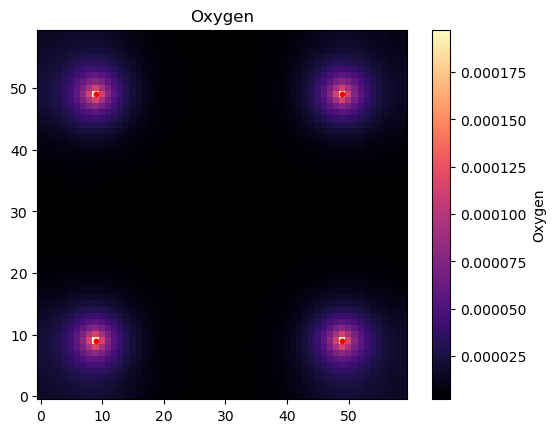

In [13]:
import matplotlib.pyplot as plt
import os

output_dir = "29052926_4vessels"
os.makedirs(output_dir, exist_ok=True)


# Second figure: oxygen map
plt.figure()
plt.imshow(O_history[tmax].T,origin='lower',cmap='magma')
plt.colorbar(label='Oxygen')

# oxygen source mask - active
ys_active, xs_active = np.where(O_original_interior_mask & O_mask_history[tmax])
plt.scatter(ys_active, xs_active, marker='.', color='red', s=30, linewidths=1.5, label='Active Oxygen Sources')

# oxygen source mask - clogged
ys_clog, xs_clog = np.where(O_original_interior_mask & (~O_mask_history[tmax]))
plt.scatter(ys_clog, xs_clog, marker='x', color='red', s=30, linewidths=1.5, label='Clogged Oxygen Sources')
plt.title('Oxygen')
plt.savefig(os.path.join(output_dir, "oxygen_map_long.png"), dpi=300, bbox_inches='tight')

plt.show()


In [6]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np

times_to_plot = list(range(0, 251))

for t in times_to_plot:
    plt.figure()
    
    # plot density
    lgca.plot_density(lgca.dens_t[t].reshape(1, -1), cmap='viridis')  # reshape 1D → 2D
    ax = plt.gca()
    
    # oxygen data
    oxygen_data = O_history[t].T 
    x = np.arange(oxygen_data.shape[1])
    y = np.arange(oxygen_data.shape[0])
    
    lowox = lgca.interaction_params['lowox'] 
    ultralowox = lgca.interaction_params['ultralowox']
    
    # contours
    ax.contour(x, y, oxygen_data, levels=[lowox], colors='cyan', linewidths=3, linestyles='solid')
    ax.contour(x, y, oxygen_data, levels=[ultralowox], colors='orange', linewidths=3, linestyles='solid')
    
    # Legend handles
    low_handle = mlines.Line2D([], [], color='cyan', linestyle='solid', label='Hypoxia')
    ultralow_handle = mlines.Line2D([], [], color='orange', linestyle='solid', label='Anoxia')
        
    # oxygen source mask - active
    ys_active, xs_active = np.where(O_original_interior_mask & O_mask_history[t])
    source_handle = plt.scatter(ys_active, xs_active, marker='.', color='red', s=30, linewidths=1.5, label='Active Oxygen Sources')
    
    # oxygen source mask - clogged
    ys_clog, xs_clog = np.where(O_original_interior_mask & (~O_mask_history[t]))
    clog_handle = plt.scatter(ys_clog, xs_clog, marker='x', color='red', s=30, linewidths=1.5, label='Clogged Oxygen Sources')

    
    handles = [low_handle, ultralow_handle, source_handle, clog_handle]
    ax.legend(handles=handles, loc='upper right')
    
    plt.savefig(os.path.join(output_dir, f"density_with_oxygen_zones_long_t{t}.png"), dpi=300, bbox_inches='tight')
    plt.close()

NameError: name 'lgca' is not defined

<Figure size 640x480 with 0 Axes>

In [7]:
from PIL import Image
import os

frames = []
for t in times_to_plot:
    path = os.path.join(output_dir, f"density_with_oxygen_zones_long_t{t}.png")
    frames.append(Image.open(path))

frames[0].save(
    os.path.join(output_dir, "29052026_2d_4vessels_lgca.gif"),
    save_all=True,
    append_images=frames[1:],
    duration=150,  # milliseconds per frame
    loop=0
)

NameError: name 'output_dir' is not defined

In [1]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

# make gif
ani = lgca.animate_density(interval=100)
gif_path = "lgca_density_29052026.gif"
ani.save(gif_path, writer="pillow", fps=5)

NameError: name 'lgca' is not defined

In [18]:
#play gif
#display(Image(filename=gif_path))

# More Extra Code

In [ ]:
import matplotlib.pyplot as plt
title_str = '1'
filename_tag = title_str

plt.figure()
plt.imshow(O_history, aspect='auto', origin='lower', cmap='magma')
plt.colorbar(label='Oxygen')
plt.xlabel('Lattice node')
plt.ylabel('Time step')
plt.title(fr'Oxygen {title_str}')
plt.savefig(f"{output_dir}/oxygen_{filename_tag}.png", dpi=300)
plt.close()
                
plt.figure()
lgca.plot_density(cmap='magma')
plt.title(fr'Cell Density {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/density_{filename_tag}.png", dpi=300)
plt.close()
        
plt.figure()
lgca.plot_prop_spatial(propname='kappa', cbarlabel=r'Switch parameter $\kappa$', cmap='magma')
plt.title(fr'κ Distribution {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/kappa_{filename_tag}.png", dpi=300)
plt.close()
        
plt.figure()
lgca.plot_prop_spatial(propname='theta', cbarlabel=r'Switch parameter $\theta$', cmap='magma')
plt.title(fr'θ Distribution {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/theta_{filename_tag}.png", dpi=300)
plt.close()
        
plt.figure()
lgca.plot_density(lgca.dead_dens_t,cmap='magma')
plt.title(fr'Dead Cell Density {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/dead_{filename_tag}.png", dpi=300)
plt.close()
                
plt.figure()
lgca.plot_density(lgca.channel_pop_t[...,-1],cmap='magma')
plt.title(fr'Proliferating Cell Density {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/proliferating_{filename_tag}.png", dpi=300)
plt.close()
        
plt.figure()
lgca.plot_density(lgca.channel_pop_t[...,:-1].sum(axis=-1),cmap='magma')
plt.title(fr'Migrating Cell Density {title_str}')
plt.xlim(0, l)
plt.savefig(f"{output_dir}/migrating_{filename_tag}.png", dpi=300)
plt.close()

# kappa histogram
mean_kappa = lgca.mean_prop_t['kappa']
all_vals_k = []
for t in range(tmax-100, tmax):
    vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
    #print(f"t={t}, vals_k size={len(vals_k)}")
    all_vals_k.append(vals_k)
all_vals_k = np.concatenate(all_vals_k)
plt.figure()
plt.hist(all_vals_k, bins=30, linewidth=1)
plt.xlabel("κ")
plt.ylabel("Count")
plt.title((fr'Kappa Distribution {title_str}'))
plt.tight_layout()
plt.savefig(f"{output_dir}/kappa_hist_all_{filename_tag}.png", dpi=300)
plt.close()
                
      
# kappa and theta plots
mean_kappa = lgca.mean_prop_t['kappa']
mean_theta = lgca.mean_prop_t['theta']

# last 100 timesteps
all_vals_k = []
for t in range(tmax-100, tmax):
    vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
    if len(vals_k) > 0:
        all_vals_k.append(vals_k)
all_vals_t = []
for t in range(tmax-100, tmax):
    vals_t = mean_theta[t].compressed() if hasattr(mean_theta[t], "compressed") else mean_theta[t]
    if len(vals_t) > 0:
        all_vals_t.append(vals_t)
window_used = 100
                
# try last 200 if either is empty
if len(all_vals_k) == 0 or len(all_vals_t) == 0:
    all_vals_k = []
    for t in range(tmax-200, tmax):
        vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
        if len(vals_k) > 0:
            all_vals_k.append(vals_k)
    all_vals_t = []
    for t in range(tmax-200, tmax):
        vals_t = mean_theta[t].compressed() if hasattr(mean_theta[t], "compressed") else mean_theta[t]
        if len(vals_t) > 0:
            all_vals_t.append(vals_t)
    window_used = 200
                
# still empty? skip
if len(all_vals_k) == 0 or len(all_vals_t) == 0:
    print(f"Skipping κ/θ histograms for {filename_tag}: no values in last 100 or 200 steps.")
    continue
                
all_vals_k = np.concatenate(all_vals_k)
all_vals_t = np.concatenate(all_vals_t)

# kappa histogram
plt.figure()
plt.hist(all_vals_k, bins=30, linewidth=1)
plt.xlabel("κ")
plt.ylabel("Count")
plt.title(fr'Kappa Distribution {title_str} (last {window_used} steps)')
plt.tight_layout()
plt.savefig(f"{output_dir}/kappa_hist_all_{filename_tag}.png", dpi=300)
plt.close()

# theta histogram
plt.figure()
plt.hist(all_vals_t, bins=30, linewidth=1)
plt.xlabel("θ")
plt.ylabel("Count")
plt.title(fr'Theta Distribution {title_str} (last {window_used} steps)')
plt.tight_layout()
plt.savefig(f"{output_dir}/theta_hist_all_{filename_tag}.png", dpi=300)
plt.close()
                
                
# heat map
# range on plot
min_kappa = min(all_vals_k.min(), kappa_scan)
max_kappa = max(all_vals_k.max(), kappa_scan)
min_theta = min(all_vals_t.min(), theta_scan)
max_theta = max(all_vals_t.max(), theta_scan)
plt.figure()
counts, xedges, yedges, im = plt.hist2d(all_vals_k, all_vals_t, bins=80, range=[[min_kappa, max_kappa], [min_theta, max_theta]], cmap='viridis')
plt.xlabel("κ")
plt.ylabel("θ")
#plt.xlim(min_kappa, max_kappa)
#plt.ylim(min_theta, max_theta)
plt.title(f"κ–θ Heat Map {title_str}")
plt.colorbar(im, label="Frequency")
plt.plot(kappa_scan, theta_scan, marker='*', markersize=10, color='red')
plt.tight_layout()
plt.savefig(f"{output_dir}/kappa_theta_heatmap_{filename_tag}.png", dpi=300)
plt.close()

In [ ]:
import matplotlib.pyplot as plt
import os
import types
plt.close('all')
%matplotlib inline
output_dir = "12032025_figures"
os.makedirs(output_dir, exist_ok=True)

for kappa_scan in [0.5, 2, 4, 5]:
    for theta_scan in [0.2, 0.4, 0.6, 0.8]:
        for beta_scan in [0, 1]:
            for oxygen_scan in [convert_const*60,0.5*convert_const*60]:
                print(kappa_scan)
                
                lgca = get_lgca(ib=True, ve = False, nodes=nodes, geometry='1d', bc='reflect', interaction='go_or_grow', kappa=kappa_scan, theta=theta_scan)
                # these give default values
                lgca.interaction_params['capacity'] = capacity_param
                lgca.interaction_params['kappa_std'] = 0.2
                lgca.interaction_params['r_d'] = 0.01
                lgca.interaction_params['r_b'] = 0.2
                lgca.oxygen = np.zeros(lgca.cell_density.shape)
                lgca.dead_cell_density = np.zeros(lgca.cell_density.shape)
                
                lgca.mask = np.zeros_like(lgca.oxygen, dtype=bool)
                lgca.mask[1:-1:4] = True
                
                lgca.oxygen[:] = convert_const*24
                lgca.interaction_params['r_d_hypoxia'] = 0.5
                lgca.interaction_params['max_ox'] = convert_const*95

                lgca.interaction_params['lowox'] = convert_const*7
                lgca.interaction_params['ultralowox'] = convert_const*0.7

                lgca.interaction_params['kappa_clog'] = 10
                lgca.interaction_params['theta_clog'] = 0.08 # clog around 1 cells?

                lgca.interaction_params['beta'] = beta_scan
                
                # choose interaction
                lgca.interaction = go_or_grow_kappa_chemo_mod
                
                
                lgca.oxygen[:] = convert_const*24 # µmol/cm
                lgca.oxygen_source = oxygen_scan # µmol/cm
                


                lgca.timeevo_mod = types.MethodType(timeevo_mod, lgca)
                lgca.timeevo_mod(timesteps=tmax, record=True, recordN=True, recorddens=True, recorddead=True, recordox=True, recordchanneldens=True, showprogress=False, recordfampop=False)
                O_history = lgca.ox_t
                title_str = fr'β={beta_scan}, θ={theta_scan}, κ={kappa_scan}, O2={oxygen_scan}'
                filename_tag = f"b{beta_scan}_t{theta_scan}_k{kappa_scan}_o{oxygen_scan:.2e}".replace('.', 'p')
                
                plt.figure()
                plt.imshow(O_history, aspect='auto', origin='lower', cmap='magma')
                plt.colorbar(label='Oxygen')
                plt.xlabel('Lattice node')
                plt.ylabel('Time step')
                plt.title(fr'Oxygen {title_str}')
                plt.savefig(f"{output_dir}/oxygen_{filename_tag}.png", dpi=300)
                plt.close()
                
                plt.figure()
                lgca.plot_density(cmap='magma')
                plt.title(fr'Cell Density {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/density_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_prop_spatial(propname='kappa', cbarlabel=r'Switch parameter $\kappa$', cmap='magma')
                plt.title(fr'κ Distribution {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/kappa_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_prop_spatial(propname='theta', cbarlabel=r'Switch parameter $\theta$', cmap='magma')
                plt.title(fr'θ Distribution {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/theta_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_density(lgca.dead_dens_t,cmap='magma')
                plt.title(fr'Dead Cell Density {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/dead_{filename_tag}.png", dpi=300)
                plt.close()
                
                plt.figure()
                lgca.plot_density(lgca.channel_pop_t[...,-1],cmap='magma')
                plt.title(fr'Proliferating Cell Density {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/proliferating_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_density(lgca.channel_pop_t[...,:-1].sum(axis=-1),cmap='magma')
                plt.title(fr'Migrating Cell Density {title_str}')
                plt.xlim(0, l)
                plt.savefig(f"{output_dir}/migrating_{filename_tag}.png", dpi=300)
                plt.close()


                # kappa and theta plots
                mean_kappa = lgca.mean_prop_t['kappa']
                mean_theta = lgca.mean_prop_t['theta']

                # last 100 timesteps
                all_vals_k = []
                for t in range(tmax-100, tmax):
                    vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
                    if len(vals_k) > 0:
                        all_vals_k.append(vals_k)
                all_vals_t = []
                for t in range(tmax-100, tmax):
                    vals_t = mean_theta[t].compressed() if hasattr(mean_theta[t], "compressed") else mean_theta[t]
                    if len(vals_t) > 0:
                        all_vals_t.append(vals_t)
                window_used = 100
                
                # try last 200 if either is empty
                if len(all_vals_k) == 0 or len(all_vals_t) == 0:
                    all_vals_k = []
                    for t in range(tmax-200, tmax):
                        vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
                        if len(vals_k) > 0:
                            all_vals_k.append(vals_k)
                    all_vals_t = []
                    for t in range(tmax-200, tmax):
                        vals_t = mean_theta[t].compressed() if hasattr(mean_theta[t], "compressed") else mean_theta[t]
                        if len(vals_t) > 0:
                            all_vals_t.append(vals_t)
                    window_used = 200
                
                # still empty? skip
                if len(all_vals_k) == 0 or len(all_vals_t) == 0:
                    print(f"Skipping κ/θ histograms for {filename_tag}: no values in last 100 or 200 steps.")
                    continue
                
                all_vals_k = np.concatenate(all_vals_k)
                all_vals_t = np.concatenate(all_vals_t)

                # kappa histogram
                plt.figure()
                plt.hist(all_vals_k, bins=30, linewidth=1)
                plt.xlabel("κ")
                plt.ylabel("Count")
                plt.title(fr'Kappa Distribution {title_str} (last {window_used} steps)')
                plt.tight_layout()
                plt.savefig(f"{output_dir}/kappa_hist_all_{filename_tag}.png", dpi=300)
                plt.close()

                # theta histogram
                plt.figure()
                plt.hist(all_vals_t, bins=30, linewidth=1)
                plt.xlabel("θ")
                plt.ylabel("Count")
                plt.title(fr'Theta Distribution {title_str} (last {window_used} steps)')
                plt.tight_layout()
                plt.savefig(f"{output_dir}/theta_hist_all_{filename_tag}.png", dpi=300)
                plt.close()
                
                
                # heat map
                # range on plot
                min_kappa = min(all_vals_k.min(), kappa_scan)
                max_kappa = max(all_vals_k.max(), kappa_scan)
                min_theta = min(all_vals_t.min(), theta_scan)
                max_theta = max(all_vals_t.max(), theta_scan)
                plt.figure()
                counts, xedges, yedges, im = plt.hist2d(all_vals_k, all_vals_t, bins=80, range=[[min_kappa, max_kappa], [min_theta, max_theta]], cmap='viridis')
                plt.xlabel("κ")
                plt.ylabel("θ")
                #plt.xlim(min_kappa, max_kappa)
                #plt.ylim(min_theta, max_theta)
                plt.title(f"κ–θ Heat Map {title_str}")
                plt.colorbar(im, label="Frequency")
                plt.plot(kappa_scan, theta_scan, marker='*', markersize=10, color='red')
                plt.tight_layout()
                plt.savefig(f"{output_dir}/kappa_theta_heatmap_{filename_tag}.png", dpi=300)
                plt.close()
                                
print('finished :)')

In [ ]:
# kappa histogram
                mean_kappa = lgca.mean_prop_t['kappa']
                all_vals_k = []
                for t in range(tmax-100, tmax):
                    vals_k = mean_kappa[t].compressed() if hasattr(mean_kappa[t], "compressed") else mean_kappa[t]
                    #print(f"t={t}, vals_k size={len(vals_k)}")
                    all_vals_k.append(vals_k)
                all_vals_k = np.concatenate(all_vals_k)
                plt.figure()
                plt.hist(all_vals_k, bins=30, linewidth=1)
                plt.xlabel("κ")
                plt.ylabel("Count")
                plt.title((fr'Kappa Distribution {title_str}'))
                plt.tight_layout()
                plt.savefig(f"{output_dir}/kappa_hist_all_{filename_tag}.png", dpi=300)
                plt.close()
                                
                # theta histogram
                mean_theta = lgca.mean_prop_t['theta']
                all_vals_t = []
                for t in range(tmax-100, tmax):
                    vals_t = mean_theta[t].compressed() if hasattr(mean_theta[t], "compressed") else mean_theta[t]
                    all_vals_t.append(vals_t)
                all_vals_t = np.concatenate(all_vals_t)
                plt.figure()
                plt.hist(all_vals_t, bins=30, linewidth=1)
                plt.xlabel("θ")
                plt.ylabel("Count")
                plt.title((fr'Theta Distribution {title_str}'))
                plt.tight_layout()
                plt.savefig(f"{output_dir}/theta_hist_all_{filename_tag}.png", dpi=300)
                plt.close()

In [ ]:
plt.figure()
lgca.plot_density(cmap='magma')
plt.title('Cell Density')
plt.xlim(0, 100)

In [ ]:
plt.figure()
lgca.plot_prop_spatial(propname='kappa', cbarlabel=r'Switch parameter $\kappa$', cmap='magma')
plt.xlim(0, 100)

In [ ]:
plt.clf() 
plt.figure()
lgca.plot_prop_spatial(propname='theta', cbarlabel=r'Switch parameter $\theta$', cmap='magma')
plt.xlim(0, 200)

In [ ]:
# plot cell distribution
#plt.plot(lgca.cell_density)
#plt.xlabel('Lattice node')
#plt.ylabel('Cell density')
#plt.title('Cell distribution')
#plt.show()

In [ ]:
# dead
plt.figure()
lgca.plot_density(lgca.dead_dens_t,cmap='magma')
plt.title('Dead Cell Density')
plt.xlim(0, 100)

In [ ]:
# proliferating
lgca.plot_density(lgca.channel_pop_t[...,-1],cmap='magma', figsize=(10,10))

In [ ]:
# migrating
lgca.plot_density(lgca.channel_pop_t[...,:-1].sum(axis=-1),cmap='magma', figsize=(10,10))

In [ ]:
import matplotlib.pyplot as plt
import os
import types
plt.close('all')
%matplotlib inline
output_dir = "11date2025_figures"
os.makedirs(output_dir, exist_ok=True)

for kappa_scan in [2]: #[0.5, 2, 4, 5]:
    for theta_scan in [0.5]: #[0.2, 0.4, 0.6, 0.8]:
        for beta_scan in [1]:#[0, 1]:
            for oxygen_scan in [1.974e-6]:#[1.974e-6, 0.5*1.974e-6]:
                print(kappa_scan)
                
                lgca = get_lgca(ib=True, ve = False, nodes=nodes, geometry='1d', bc='reflect', interaction='go_or_grow', kappa=kappa_scan, theta=theta_scan)
                # these give default values
                lgca.interaction_params['capacity'] = 100
                lgca.interaction_params['kappa_std'] = 0.2
                lgca.interaction_params['r_d'] = 0.01
                lgca.interaction_params['r_b'] = 0.2
                lgca.oxygen = np.zeros(lgca.cell_density.shape)
                lgca.dead_cell_density = np.zeros(lgca.cell_density.shape)
                lgca.oxygen[:] = 7.895e-7 # micro-mol/cm
                lgca.interaction_params['r_d_hypoxia'] = 0.5
                lgca.interaction_params['max_ox'] = 3.126e-6 # micro-mol/cm
                # choose interaction
                lgca.interaction = go_or_grow_kappa_chemo_mod

                lgca.interaction_params['beta'] = beta_scan
                lgca.oxygen_source = oxygen_scan #oxygen source (vessel) every 200 um
                
                #print('kappa=', kappa_scan)
                #print('theta=', theta_scan)
                #print('beta=', beta_scan)
                #print('oxygen=', oxygen_scan)

                lgca.timeevo_mod = types.MethodType(timeevo_mod, lgca)
                lgca.timeevo_mod(timesteps=tmax, record=True, recordN=True, recorddens=True, recorddead=True, recordox=True, recordchanneldens=True, showprogress=False, recordfampop=False)
                O_history = lgca.ox_t
                title_str = fr'β={beta_scan}, θ={theta_scan}, κ={kappa_scan}, O2={oxygen_scan}'
                filename_tag = f"b{beta_scan}_t{theta_scan}_k{kappa_scan}_o{oxygen_scan:.2e}".replace('.', 'p')
                
                plt.figure()
                plt.imshow(O_history, aspect='auto', origin='lower', cmap='magma')
                plt.colorbar(label='Oxygen')
                plt.xlabel('Lattice node')
                plt.ylabel('Time step')
                plt.title(fr'Oxygen {title_str}')
                plt.savefig(f"{output_dir}/oxygen_{filename_tag}.png", dpi=300)
                plt.close()
                
                plt.figure()
                lgca.plot_density(cmap='magma')
                plt.title(fr'Cell Density {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/density_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_prop_spatial(propname='kappa', cbarlabel=r'Switch parameter $\kappa$', cmap='magma')
                plt.title(fr'κ Distribution {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/kappa_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_prop_spatial(propname='theta', cbarlabel=r'Switch parameter $\theta$', cmap='magma')
                plt.title(fr'θ Distribution {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/theta_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_density(lgca.dead_dens_t,cmap='magma')
                plt.title(fr'Dead Cell Density {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/dead_{filename_tag}.png", dpi=300)
                plt.close()
                
                plt.figure()
                lgca.plot_density(lgca.channel_pop_t[...,-1],cmap='magma')
                plt.title(fr'Proliferating Cell Density {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/proliferating_{filename_tag}.png", dpi=300)
                plt.close()
        
                plt.figure()
                lgca.plot_density(lgca.channel_pop_t[...,:-1].sum(axis=-1),cmap='magma')
                plt.title(fr'Migrating Cell Density {title_str}')
                plt.xlim(0, 300)
                plt.savefig(f"{output_dir}/migrating_{filename_tag}.png", dpi=300)
                plt.close()
print('finished :)')